# Beat 4: CAM (Class Activation Mapping)

**Pergunta:** CAM: e se eu tirar o FC?

Este notebook demonstra a cirurgia na arquitetura ResNet-18 (`conv → GAP → fc`), a extração do mapa CAM via hook e o impacto de acurácia de 2,98% top-1.

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

import deck
from gradcam import cam
from gradcam.core import resolve_layer
from gradcam.models import load_model, preprocess, imagenet_labels
from gradcam.viz import figure_grid, overlay, tensor_to_numpy
from gradcam.models import denormalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("resnet18", device=device)
labels = imagenet_labels()
print(f"ResNet-18 carregado em {device}")

ResNet-18 carregado em cpu


## Calculando o CAM na ResNet-18

Utilizando o hook na última camada convolucional antes do Global Average Pooling.

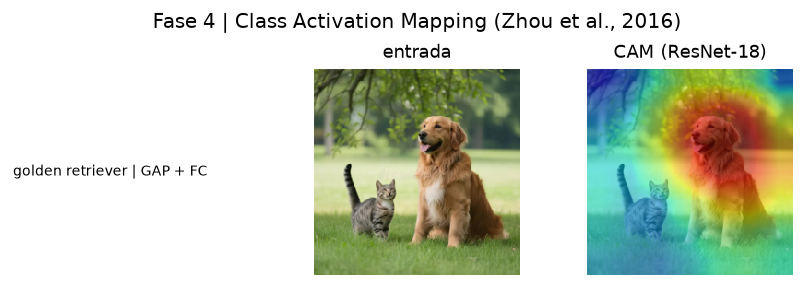

Classe: golden retriever | Camada: Conv2d | Mapa shape: (7, 7)


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

class_idx = int(model(x).argmax(dim=1).item())
layer = resolve_layer(model)

cam_map, _ = cam(model, x, class_idx=class_idx, layer=layer)
cam_map = cam_map.detach()

DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, cam_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ]
    ],
    col_titles=("entrada", "CAM (ResNet-18)"),
    row_titles=[f"{labels[class_idx]} | GAP + FC"],
    suptitle="Fase 4 | Class Activation Mapping (Zhou et al., 2016)",
)
plt.show()

print(f"Classe: {labels[class_idx]} | Camada: {layer.__class__.__name__} | Mapa shape: {tuple(cam_map.shape)}")